# Health Programme Demand and Skills

## Purpose
This notebook provides an overview of job-posting demand, study places, and skills mentioned in Norwegian health-sector job postings.

## Data
The charts use the processed CSV files in `data/processed/`:
- NAV postings, classified by health programme
- Study places from Samordna opptak 2026
- Skills matched against Norwegian ESCO labels

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/processed").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"

# Estimated postings over the last 12 months (same numbers as the ranking).
demand = pd.read_csv(DATA / "demand_history_by_programme.csv")
demand["postings"] = demand["postings_estimated"].astype(int)
gap = pd.read_csv(DATA / "gap_by_programme.csv")
skills = pd.read_csv(DATA / "skills_by_programme.csv")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

### Job postings by programme

This chart shows the estimated number of NAV job postings for each health programme over the last 12 months. These are the same demand numbers used in the ranking. The counts are estimated from job titles and corrected with the current postings, where NAV's occupation code gives the right programme. Posting counts indicate observed demand, but do not by themselves measure the number of unfilled positions or the size of a workforce shortage.

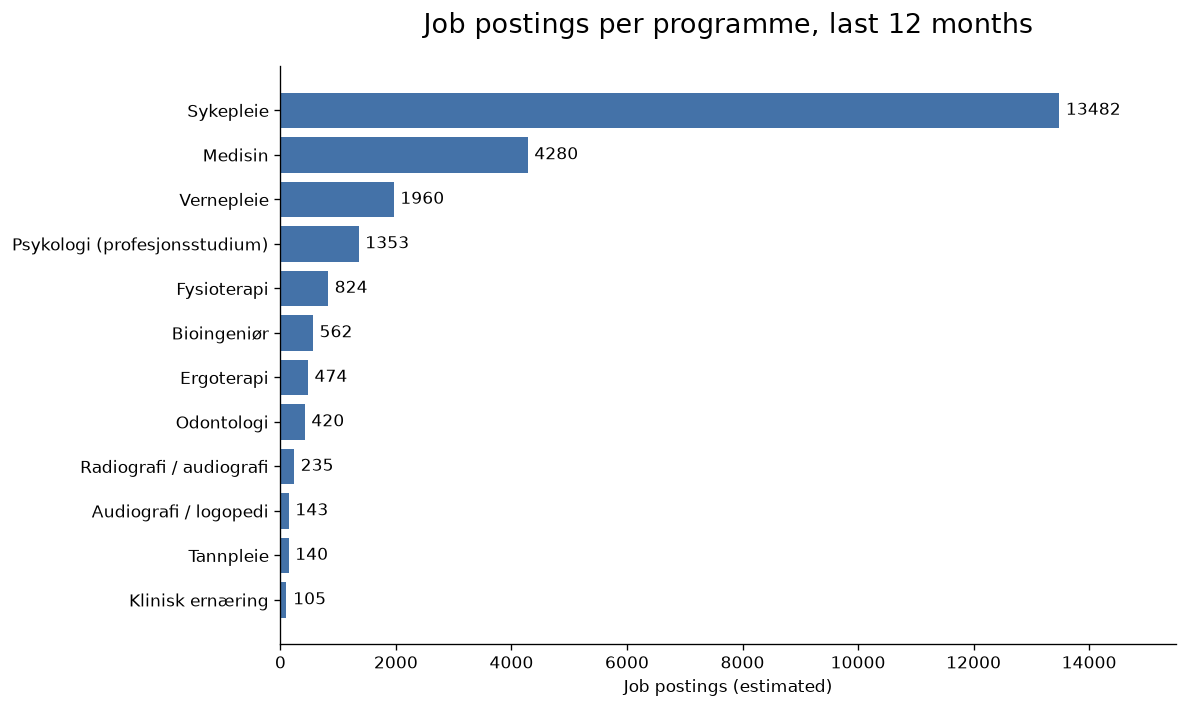

In [2]:
plot_data = demand.sort_values("postings")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_data["programme"], plot_data["postings"], color="#4472A8")

ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_xlim(0, plot_data["postings"].max() * 1.15)
ax.set_title("Job postings per programme, last 12 months", fontsize=16, pad=20)
ax.set_xlabel("Job postings (estimated)")
ax.set_ylabel("")

fig.tight_layout()
fig.savefig(FIGURES / "job_postings_per_programme.png", bbox_inches="tight", dpi=200)
plt.show()

### Postings relative to study places

This chart compares job-posting demand with the number of study places in each programme. A higher value means more postings relative to the available places. This ratio is an indicator for comparison, not proof of a workforce shortage or a guarantee that adding study places would address one.

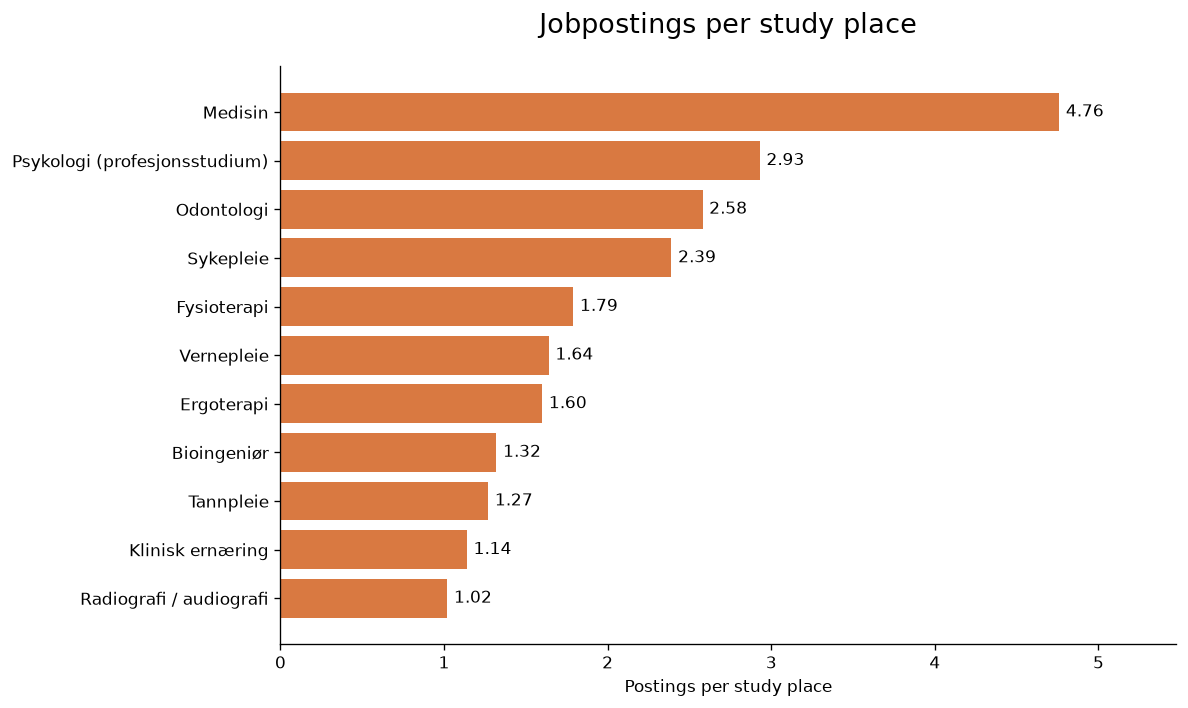

In [3]:
plot_data = gap.sort_values("postings_per_place")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data["programme"],
    plot_data["postings_per_place"],
    color="#D97941",
)

ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlim(0, plot_data["postings_per_place"].max() * 1.15)
ax.set_title("Jobpostings per study place", fontsize=16, pad=20)
ax.set_xlabel("Postings per study place")
ax.set_ylabel("")

fig.tight_layout()
fig.savefig(FIGURES / "postings_per_study_place.png", bbox_inches="tight", dpi=200)
plt.show()

### Skills mentioned in job postings

For each programme, this chart shows the five skills with the highest share of postings that mention them. Bar colours indicate whether a skill is listed as essential, optional, or not included in the selected ESCO occupation profile. Skill matching is based on Norwegian ESCO labels, so paraphrases may not be detected.

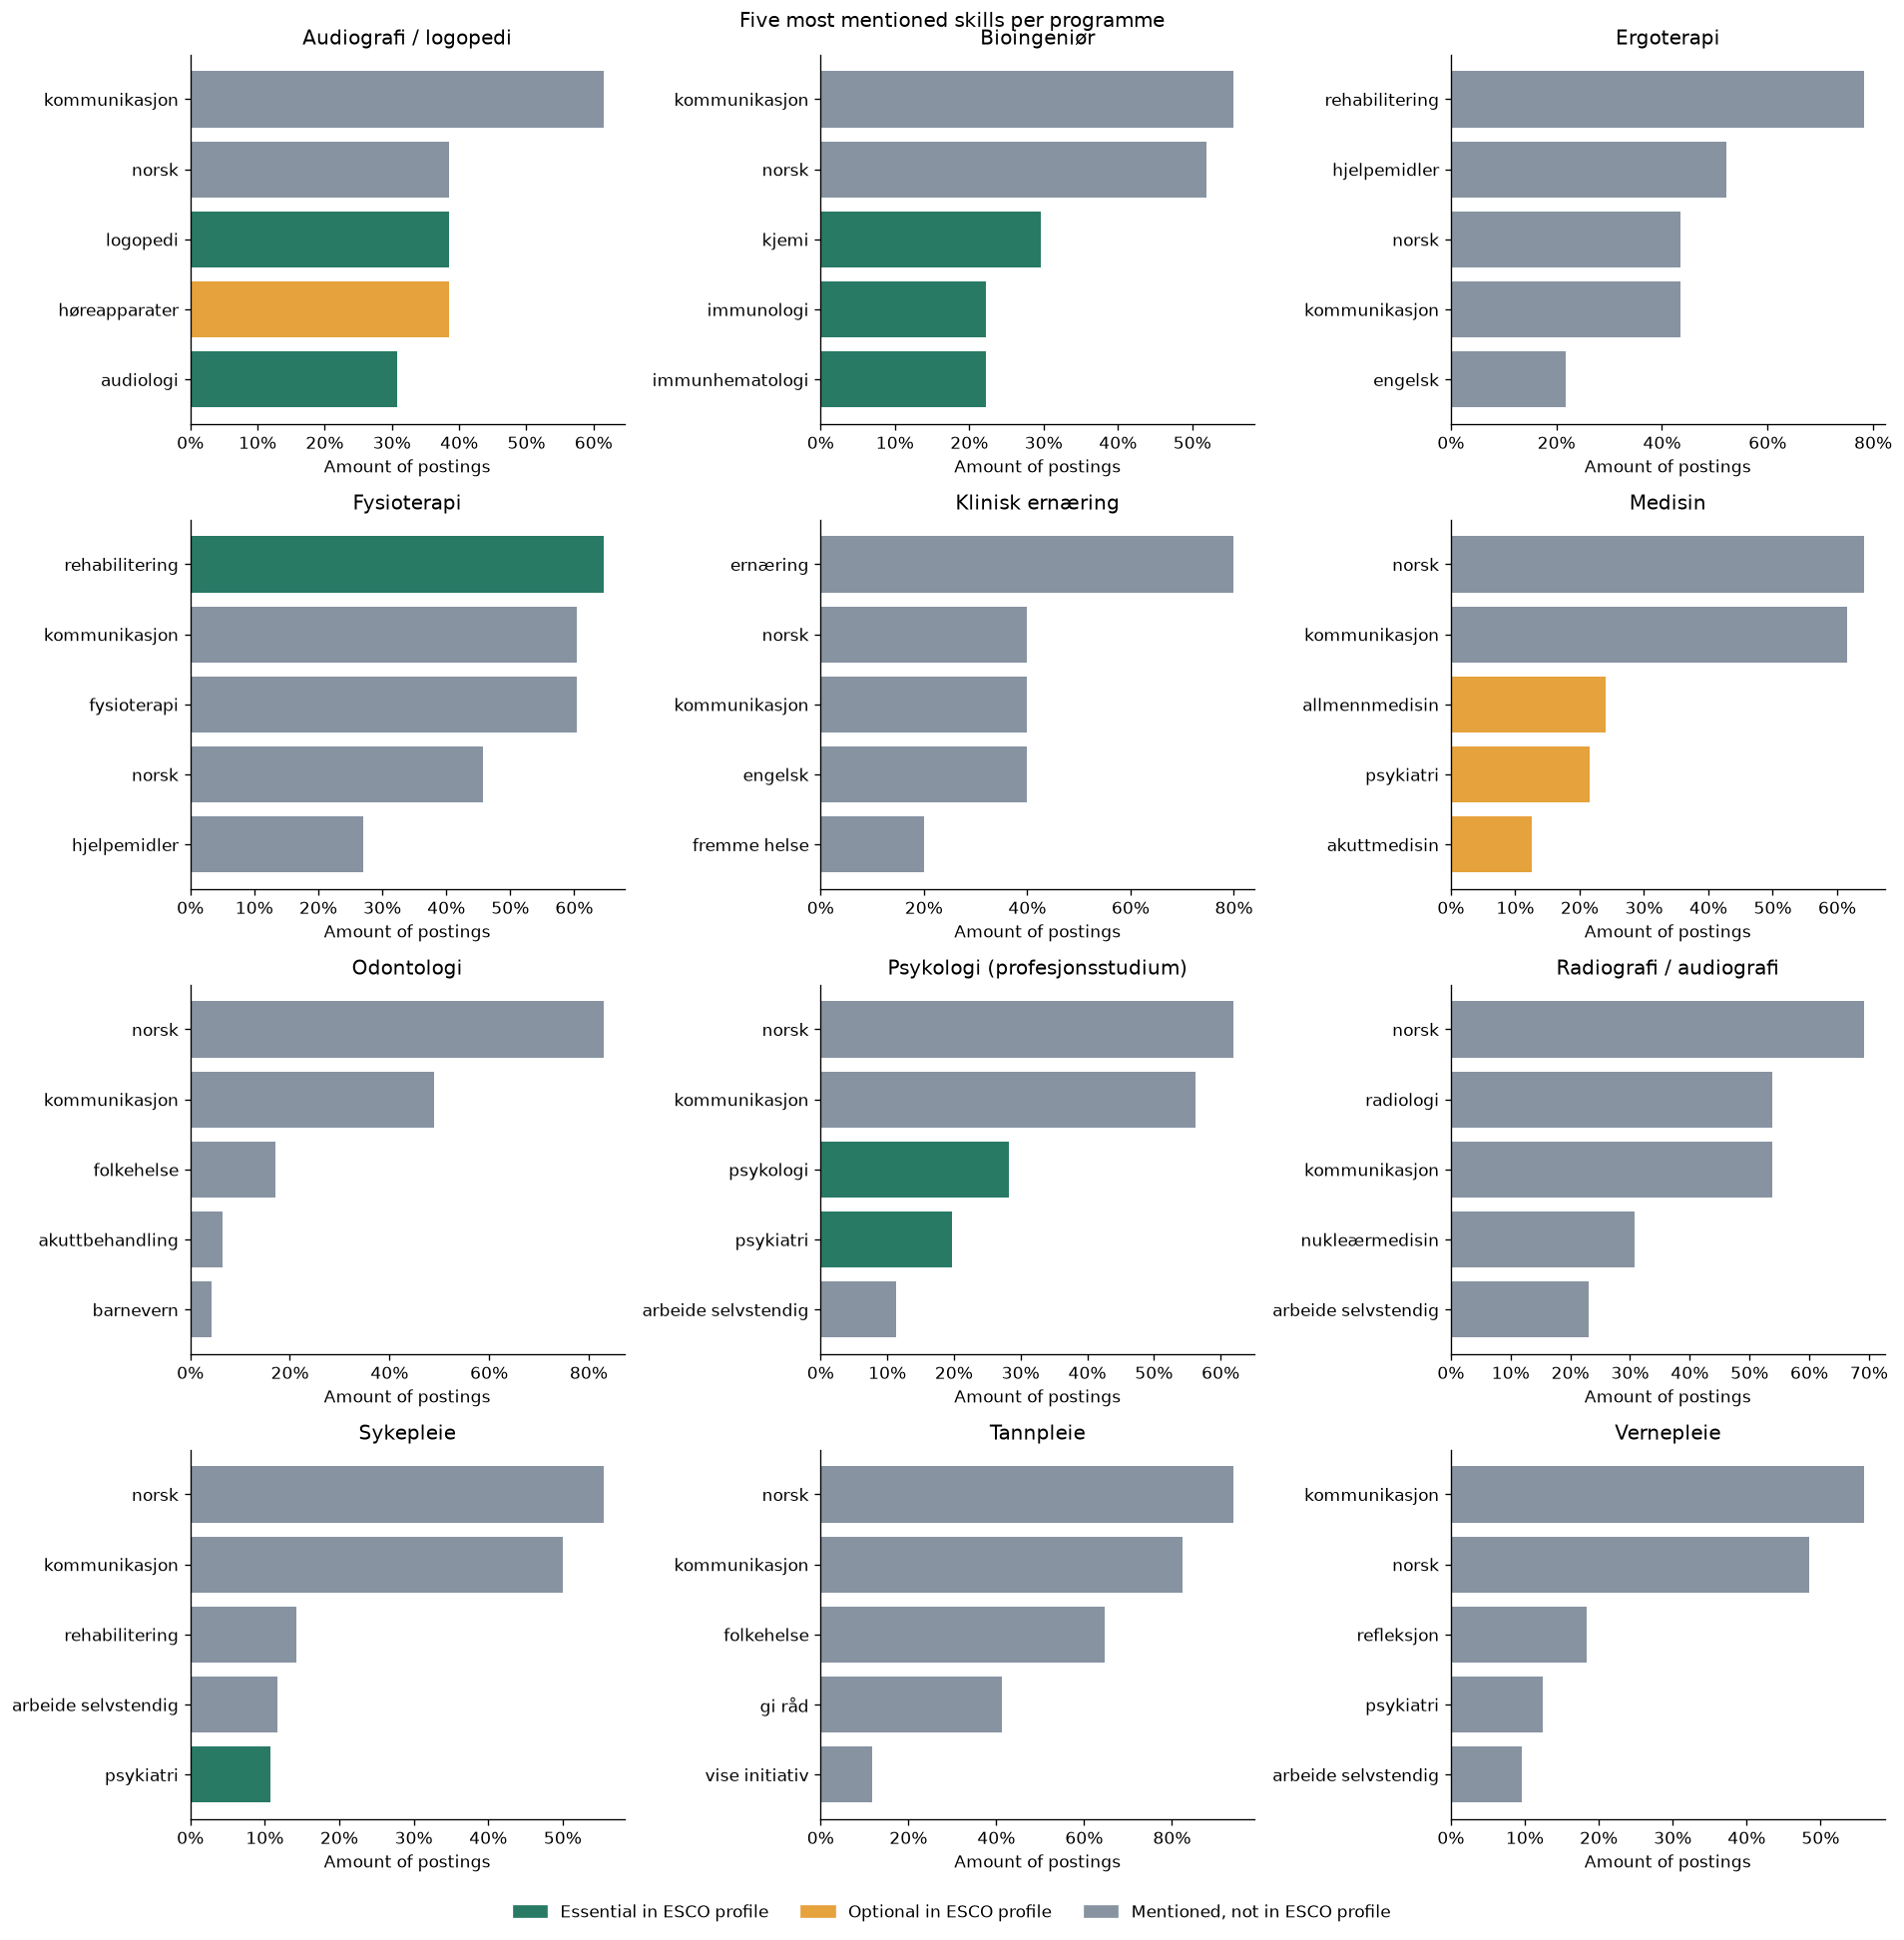

In [3]:
from math import ceil
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

colors = {
    "essential": "#287A65",
    "optional": "#E6A23C",
    "none": "#8793A1",
}
relation_labels = {
    "essential": "Essential in ESCO profile",
    "optional": "Optional in ESCO profile",
    "none": "Mentioned, not in ESCO profile",
}

plot_data = skills[skills["n_postings"] > 0].copy()
programmes = sorted(plot_data["programme"].dropna().unique())

ncols = 3
nrows = ceil(len(programmes) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for ax, programme in zip(axes, programmes):
    top = (
        plot_data[plot_data["programme"] == programme]
        .nlargest(5, "share_postings")
        .sort_values("share_postings")
    )
    bar_colors = top["esco_relation"].map(colors).fillna("#8793A1")

    ax.barh(top["skill"], top["share_postings"], color=bar_colors)
    ax.set_title(programme)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Amount of postings")
    ax.set_ylabel("")

for ax in axes[len(programmes):]:
    ax.set_visible(False)

legend = [
    Patch(color=colors[key], label=relation_labels[key])
    for key in colors
]
fig.suptitle("Five most mentioned skills per programme")
fig.tight_layout()
fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3, frameon=False)
fig.savefig(FIGURES / "top_skills_per_programme.png", bbox_inches="tight", dpi=200)
plt.show()

### Skills mentioned in job postings

For the three highest-ranked programmes by job postings per study place, this chart shows the five skills with the highest share of postings that mention them. Bar colours indicate whether a skill is listed as essential, optional, or not included in the selected ESCO occupation profile. Skill matching is based on Norwegian ESCO labels, so paraphrases may not be detected.

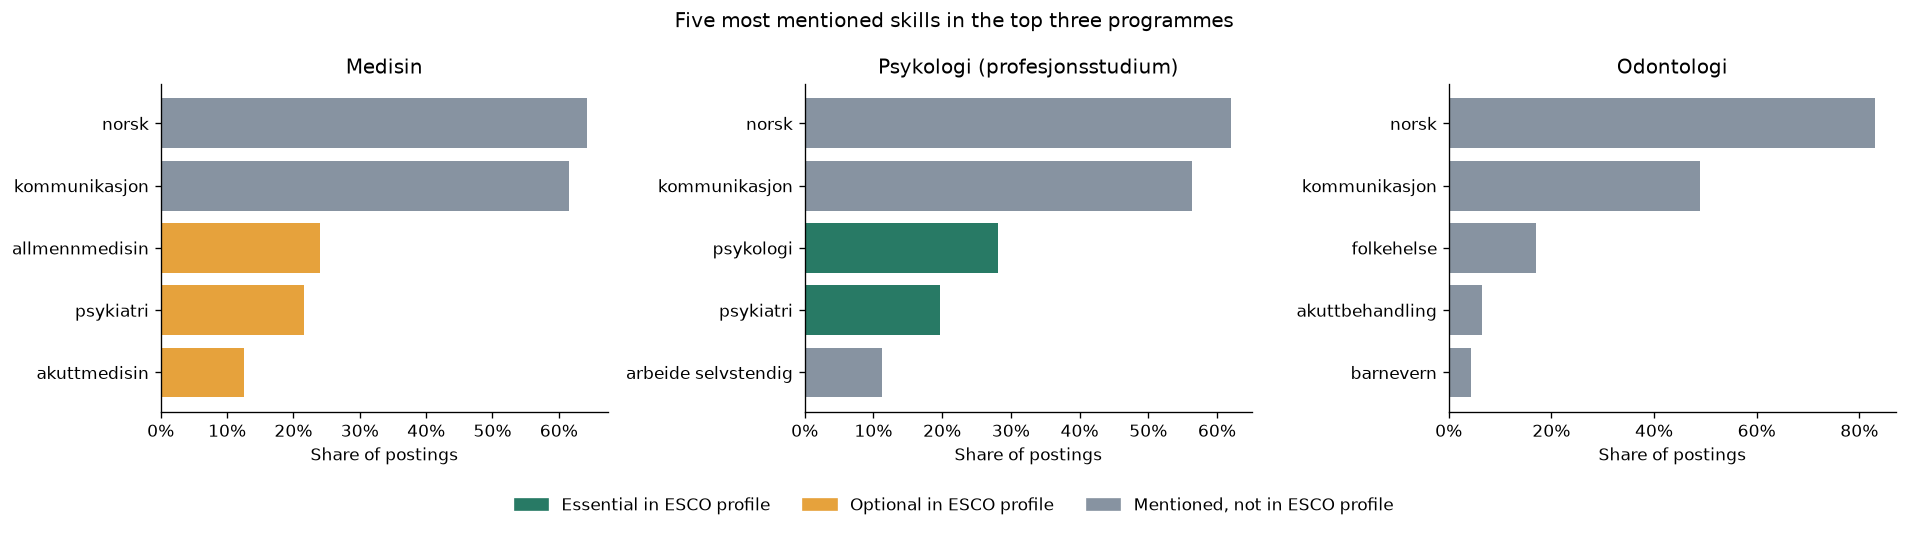

In [4]:
from math import ceil
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

colors = {
    "essential": "#287A65",
    "optional": "#E6A23C",
    "none": "#8793A1",
}
relation_labels = {
    "essential": "Essential in ESCO profile",
    "optional": "Optional in ESCO profile",
    "none": "Mentioned, not in ESCO profile",
}

plot_data = skills[skills["n_postings"] > 0].copy()
top_programmes = (
    pd.read_csv(DATA.parent / "eval" / "ranking_ranks.csv")
    .nsmallest(3, "rank_method")["programme"]
    .tolist()
)
programmes = [p for p in top_programmes if p in plot_data["programme"].values]

ncols = 3
nrows = ceil(len(programmes) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for ax, programme in zip(axes, programmes):
    top = (
        plot_data[plot_data["programme"] == programme]
        .nlargest(5, "share_postings")
        .sort_values("share_postings")
    )
    bar_colors = top["esco_relation"].map(colors).fillna("#8793A1")

    ax.barh(top["skill"], top["share_postings"], color=bar_colors)
    ax.set_title(programme)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Share of postings")
    ax.set_ylabel("")

for ax in axes[len(programmes):]:
    ax.set_visible(False)

legend = [
    Patch(color=colors[key], label=relation_labels[key])
    for key in colors
]
fig.suptitle("Five most mentioned skills in the top three programmes")
fig.tight_layout()
fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3, frameon=False)
plt.show()